Relative pitch function extractor

From 2-bar MIDI segments, convert the 2nd bar into a relative pitch function.

In [9]:
# Imports section
import numpy as np
from scipy.signal import butter, filtfilt
from music21 import converter, note
import matplotlib.pyplot as plt

In [10]:
# Definition of the path to MIDI file
midi_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset/Cooley's_0_2bars_9.midi"
#midi_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/synthetics_dataset/4.midi"
#midi_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/weird_dataset/example2.mid"

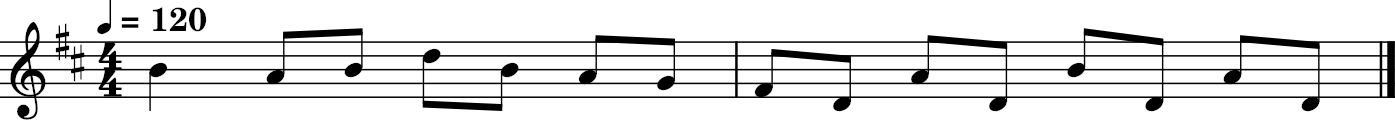

In [11]:
score = converter.parse(midi_file_path)
score.show()

In [12]:
# Definitions
positions_per_bar = 48 # decided in the paper
measeure_length = 4 # time signature is 4/4, so 4 beats per measure

onsets = []
pitches = []

pitch_vector = np.zeros(positions_per_bar, dtype=np.float32) # vector of len 48 filled with 0s

In [13]:
# Extract the notes from MIDI file
score = converter.parse(midi_file_path)

# Get only the 1st bar
score = score.measure(1)
score = score.flat.notes

for n in score:
    if isinstance(n, note.Note):
        onsets.append(n.offset)
        pitches.append(n.pitch.midi)

# Convert to numpy arrays
onsets = np.array(onsets, dtype=np.float32)
pitches = np.array(pitches, dtype=np.int16)

# Convert note onset (offset in beats) to a grid position [0..47]
# Get relative time inside the measure
norm_onsets = np.mod(onsets, measeure_length) / measeure_length
# Map to 48-step grid
quant_onsets = np.round(norm_onsets * (positions_per_bar - 1)).astype(int)

onsets = quant_onsets
print(onsets)
print(pitches)

# Fill the pitch_vector
# Sustain each note until the next onset
for i, onset in enumerate(onsets):
    if i + 1 < len(onsets):
        end = onsets[i + 1]
    else:
        end = positions_per_bar
    pitch_vector[onset:end] = pitches[i]

print(pitch_vector)
print(pitch_vector.shape)

[ 0 12 18 24 29 35 41]
[71 69 71 74 71 69 67]
[71. 71. 71. 71. 71. 71. 71. 71. 71. 71. 71. 71. 69. 69. 69. 69. 69. 69.
 71. 71. 71. 71. 71. 71. 74. 74. 74. 74. 74. 71. 71. 71. 71. 71. 71. 69.
 69. 69. 69. 69. 69. 67. 67. 67. 67. 67. 67. 67.]
(48,)


In [14]:
# Compute relative pitch function

# Definition of the constant variables
num_points = 512
filter_cutoff = 1/50
filter_order = 5 # not in the paper, but 5 is a typical value for how steep the roll-off is

# Piecewise-linear interpolation
x = np.linspace(onsets.min(), onsets.max(), num_points)
y = np.interp(x, onsets, pitches)

# Low-pass Butterworth filtering
# to smooth the linear interpolation
b, a = butter(filter_order, filter_cutoff, btype='low')
y_smooth = filtfilt(b, a, y)

# Normalization
# Find midpoint in the curve range
pitch_range = y_smooth.max() - y_smooth.min()
middle_val = y_smooth.min() + pitch_range/2

# Substract midpoint and divide by 12
# 12 because 12 semitones = 1 octave
frp = (y_smooth - middle_val) / 12.0

print(frp.shape)

(512,)


C:\Users\cristinj\AppData\Local\Temp\ipykernel_26228\3510709496.py:1: StreamIteratorInefficientWarning: show is not defined on StreamIterators. Call .stream() first for efficiency
  score.show()
c:\Users\cristinj\OneDrive - Universitetet i Oslo\Documents\Project1\melodic-contour-generation-based-on-sketches\venv\lib\site-packages\music21\musicxml\m21ToXml.py:428: MusicXMLWarning: <music21.stream.Score 0x1ca02426740> is not well-formed; see isWellFormedNotation()
  warnings.warn(f'{sc} is not well-formed; see isWellFormedNotation()',


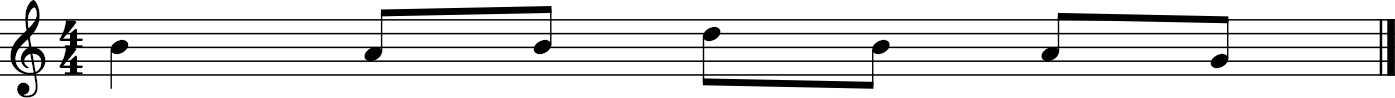

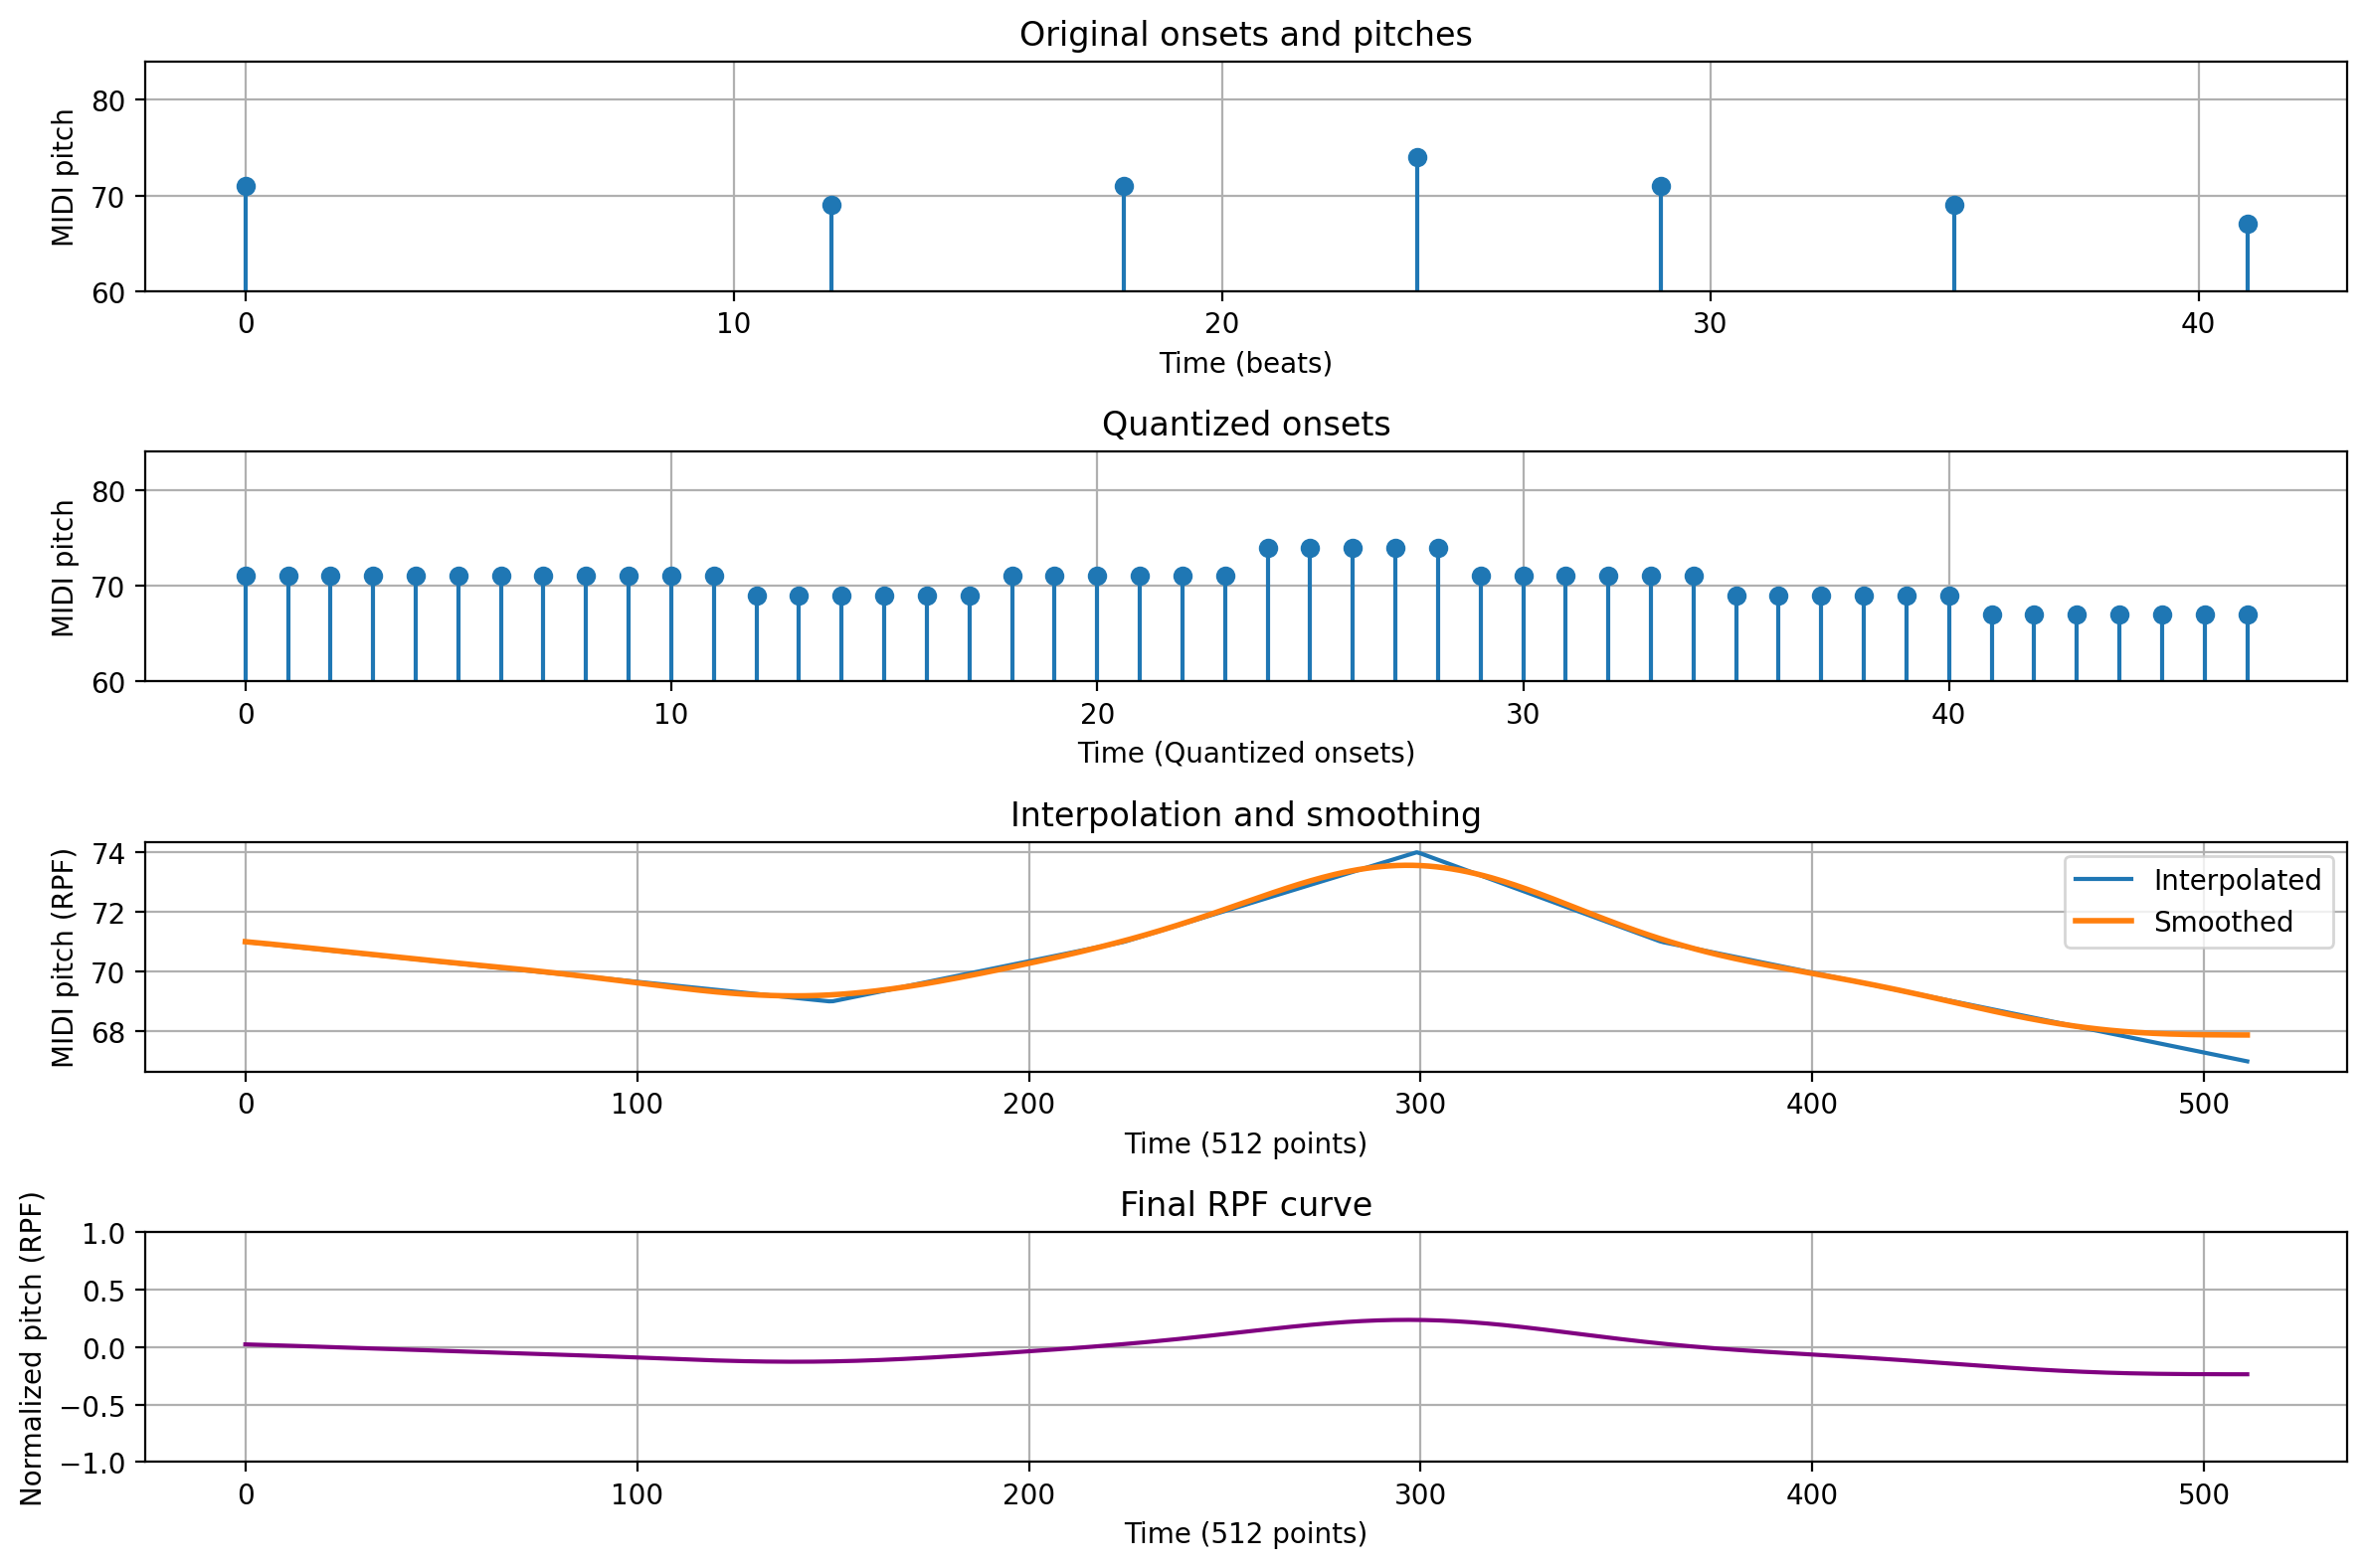

In [15]:
score.show()

plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.stem(onsets, pitches, basefmt=" ")
plt.title("Original onsets and pitches")
plt.xlabel("Time (beats)")
plt.ylabel("MIDI pitch")
plt.ylim(60, 84)  # two octaves around middle C
plt.grid(True)

plt.subplot(4, 1, 2)
plt.stem(pitch_vector, basefmt=" ")
plt.title("Quantized onsets")
plt.xlabel("Time (Quantized onsets)")
plt.ylabel("MIDI pitch")
plt.ylim(60, 84)
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(y, label='Interpolated')
plt.plot(y_smooth, label='Smoothed', linewidth=2)
plt.title("Interpolation and smoothing")
plt.xlabel("Time (512 points)")
plt.ylabel("MIDI pitch (RPF)")
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(frp, color='purple')
plt.title("Final RPF curve")
plt.xlabel("Time (512 points)")
plt.ylabel("Normalized pitch (RPF)")
plt.ylim(-1, 1)
plt.grid(True)

plt.tight_layout()
plt.show()

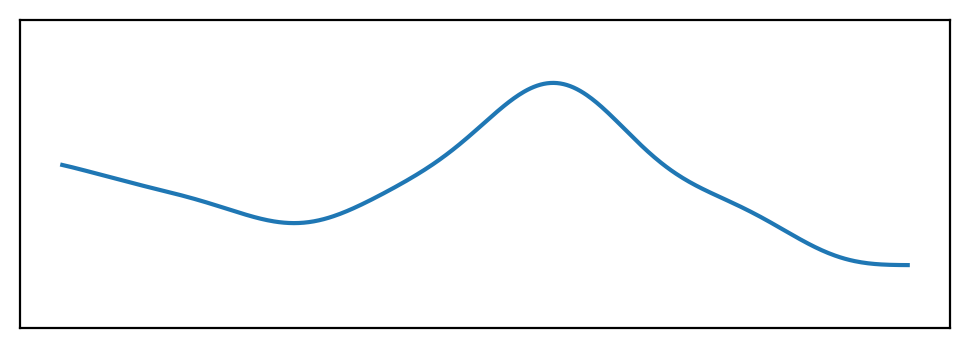

In [ ]:
plt.figure(figsize=(6, 2))
plt.plot(frp)
#plt.title("Relative Pitch Function (Frp)")
#plt.xlabel("512 samples across 2nd measure")
#plt.ylabel("Relative pitch (octaves)")
plt.yticks([])
plt.xticks([])
plt.ylim(-0.4, 0.4)
#plt.xlim(0, 512)
#plt.xticks(fontsize=12)
#plt.grid(True)
plt.show()